<a href="https://colab.research.google.com/github/Err0r404G/Assignment-MID-CVPR/blob/main/Assignment_CNN_Pineapple_Leaf_Disease.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install torchsummary on Google Colab
try:
    import torchsummary
except ImportError:
    !pip -q install torchsummary


## 1. Import Libraries


In [ ]:
import os
import zipfile
from pathlib import Path

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from torch.optim import Adam
from torch import optim
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.ticker as mticker

try:
    from torchsummary import summary
except ImportError:
    def summary(model, input_size):
        print(model)
        total = sum(p.numel() for p in model.parameters())
        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print("=" * 64)
        print(f"Total params: {total:,}")
        print(f"Trainable params: {trainable:,}")
        print(f"Non-trainable params: {total - trainable:,}")
        print("=" * 64)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


Device: cuda


## 2. Load Dataset & Train / Val / Test Split


In [ ]:
# Mount Google Drive (Google Colab) and load the Pineapple Leaf Disease Dataset
from google.colab import drive
drive.mount("/content/drive")

# Update DRIVE_FOLDER if you saved the dataset in a different Google Drive folder
DRIVE_FOLDER = "/content/drive/MyDrive/CVPR DATASET"
EXTRACT_DIR  = "/content/pineapple_dataset"  # Local Colab SSD for fast training
WORK_DIR     = DRIVE_FOLDER if os.path.exists(DRIVE_FOLDER) else "/content"
os.makedirs(WORK_DIR, exist_ok=True)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
USE_ORIGINAL_ONLY = True  # Use original images to avoid train/test data leakage


def find_class_roots(base_dir):
    candidates = []
    if not os.path.exists(base_dir):
        return candidates
    for root, dirs, _ in os.walk(base_dir):
        if "__MACOSX" in root:
            continue
        valid_subdirs = []
        total_imgs = 0
        for d in sorted(dirs):
            if d.startswith(".") or d == "__MACOSX":
                continue
            sub_path = os.path.join(root, d)
            imgs = [
                f for f in os.listdir(sub_path)
                if os.path.isfile(os.path.join(sub_path, f))
                and Path(f).suffix.lower() in IMAGE_EXTS
            ]
            if len(imgs) >= 10:
                valid_subdirs.append((d, len(imgs)))
                total_imgs += len(imgs)
        if len(valid_subdirs) >= 2:
            candidates.append((root, valid_subdirs, total_imgs))
    return candidates


def extract_zips_if_needed(search_dir, target_dir):
    found = False
    if not os.path.exists(search_dir):
        return False
    for root, _, files in os.walk(search_dir):
        for fname in sorted(files):
            if fname.lower().endswith(".zip"):
                found = True
                zp = os.path.join(root, fname)
                out_dir = os.path.join(target_dir, Path(fname).stem)
                if not os.path.exists(out_dir):
                    print(f"Extracting {zp} -> {out_dir} ...")
                    os.makedirs(out_dir, exist_ok=True)
                    with zipfile.ZipFile(zp, "r") as zf:
                        zf.extractall(out_dir)
    return found


# 1) Reuse already-extracted local copy if present in this Colab session
candidates = find_class_roots(EXTRACT_DIR)

# 2) Otherwise extract any ZIP inside DRIVE_FOLDER to fast local /content SSD
if not candidates and extract_zips_if_needed(DRIVE_FOLDER, EXTRACT_DIR):
    extract_zips_if_needed(EXTRACT_DIR, EXTRACT_DIR)  # Handle nested ZIPs if any
    candidates = find_class_roots(EXTRACT_DIR)

# 3) Otherwise use already-unzipped class folders directly inside DRIVE_FOLDER
if not candidates:
    candidates = find_class_roots(DRIVE_FOLDER)

if not candidates:
    raise FileNotFoundError(
        f"Dataset not found inside '{DRIVE_FOLDER}'. "
        "Place the Pineapple Leaf Disease ZIP or extracted class folders there, "
        "or update DRIVE_FOLDER to match your Google Drive path."
    )

if USE_ORIGINAL_ONLY:
    orig = [c for c in candidates if "orig" in c[0].lower() or "orginal" in c[0].lower()]
    DATA_DIR = orig[0][0] if orig else sorted(candidates, key=lambda x: x[2])[0][0]
else:
    aug = [c for c in candidates if "aug" in c[0].lower()]
    DATA_DIR = aug[0][0] if aug else sorted(candidates, key=lambda x: x[2], reverse=True)[0][0]

class_names = sorted(
    d for d in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, d)) and not d.startswith(".")
)
num_classes = len(class_names)
class_to_idx = {c: i for i, c in enumerate(class_names)}

all_paths, all_targets = [], []
for cname in class_names:
    cdir = os.path.join(DATA_DIR, cname)
    for fname in sorted(os.listdir(cdir)):
        if Path(fname).suffix.lower() in IMAGE_EXTS:
            all_paths.append(os.path.join(cdir, fname))
            all_targets.append(class_to_idx[cname])

# Stratified split: 80% train+val / 20% test, then 10% of train+val as validation
trainval_paths, te_paths, trainval_targets, te_targets = train_test_split(
    all_paths, all_targets, test_size=0.20, stratify=all_targets, random_state=SEED
)
tr_paths, val_paths, tr_targets, val_targets = train_test_split(
    trainval_paths, trainval_targets, test_size=0.125, stratify=trainval_targets, random_state=SEED
)

print("Selected DATA_DIR:", DATA_DIR)
print(f"Classes ({num_classes}): {class_names}")
print(f"Train images : {len(tr_paths)}")
print(f"Val   images : {len(val_paths)}")
print(f"Test  images : {len(te_paths)}")


Mounted at /content/drive
Extracting /content/drive/MyDrive/CVPR DATASET/Pineapple Leaf Disease Dataset for Deep Learning-B.zip -> /content/pineapple_dataset/Pineapple Leaf Disease Dataset for Deep Learning-B ...
Selected DATA_DIR: /content/pineapple_dataset/Pineapple Leaf Disease Dataset for Deep Learning-B/Pineapple Leaf Disease Dataset for Deep Learning-B/Pineaple Orginal leaf dataset
Classes (4): ['Pineapple__leaf_blight', 'Pineapple_fusarium', 'Pineapple_healthy', 'Pineapple_mealybug_wilt']
Train images : 3237
Val   images : 463
Test  images : 926


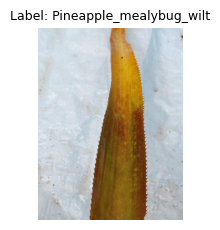

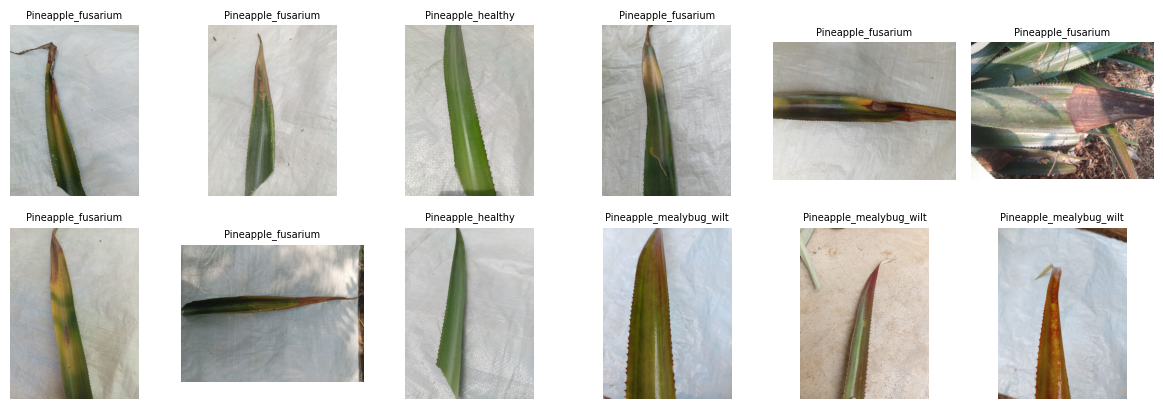

In [ ]:
# --- Sample image ---
idx = np.random.randint(0, len(tr_paths))
plt.figure(figsize=(2.5, 2.5))
plt.imshow(Image.open(tr_paths[idx]).convert("RGB"))
plt.title(f"Label: {class_names[tr_targets[idx]]}", fontsize=9)
plt.axis("off")
plt.show()

# --- Grid of sample images ---
ROWS, COLS = 2, 6
plt.figure(figsize=(12, 4.2))
sample_indices = np.random.choice(len(tr_paths), size=ROWS * COLS, replace=False)
for i, s_idx in enumerate(sample_indices):
    plt.subplot(ROWS, COLS, i + 1)
    plt.imshow(Image.open(tr_paths[s_idx]).convert("RGB"))
    plt.axis("off")
    plt.title(class_names[tr_targets[s_idx]], fontsize=7)
plt.tight_layout()
plt.show()


## 3. Data Preprocessing & Hyperparameters


In [ ]:
img_size        = 128    # 128x128 keeps leaf disease textures clear while training fast on GPU
batch_size_no   = 64     # Keeps training fast and stable on GPU
eval_batch_size = 128    # Larger batch for faster validation / test inference
learning_rate   = 1e-3   # Adam initial learning rate (decayed via ReduceLROnPlateau LRS)
epoch_number    = 14     # Same schedule as reference notebook

# Standard RGB ImageNet normalization statistics
IMG_MEAN = (0.485, 0.456, 0.406)
IMG_STD  = (0.229, 0.224, 0.225)

model_file_plain       = os.path.join(WORK_DIR, "CNN_pineapple_without_BN_Dropout.pth")
model_file_regularized = os.path.join(WORK_DIR, "CNN_pineapple_with_BN_Dropout.pth")

eval_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])


class PineappleLeafDataset(Dataset):
    """Loads and normalizes Pineapple Leaf Disease images to zero mean / unit std per channel."""
    def __init__(self, paths, targets, transform=None):
        self.paths = paths
        self.targets = targets
        self.transform = transform

    def __getitem__(self, ix):
        img = Image.open(self.paths[ix]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.targets[ix], dtype=torch.long)

    def __len__(self):
        return len(self.paths)


def get_data():
    trn_dl = DataLoader(
        PineappleLeafDataset(tr_paths, tr_targets, transform=eval_transform),
        batch_size=batch_size_no,
        shuffle=True,
        num_workers=2,
        pin_memory=(device == "cuda"),
    )
    val_dl = DataLoader(
        PineappleLeafDataset(val_paths, val_targets, transform=eval_transform),
        batch_size=eval_batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device == "cuda"),
    )
    te_dl = DataLoader(
        PineappleLeafDataset(te_paths, te_targets, transform=eval_transform),
        batch_size=eval_batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=(device == "cuda"),
    )
    return trn_dl, val_dl, te_dl


trn_dl, val_dl, te_dl = get_data()

## 4. Model Architecture


In [ ]:
def get_model(with_batch_norm=False, with_dropout=False):
    """
    Returns a CNN model, cross-entropy loss, and Adam optimizer.

    Architecture (both variants, ReLU activation only):
      Block 1 : Conv(3->32) -> Conv(32->32) -> MaxPool2d
      Block 2 : Conv(32->64) -> Conv(64->64) -> MaxPool2d
      Block 3 : Conv(64->128) -> Conv(128->128) -> MaxPool2d
      Head    : AdaptiveAvgPool(4, 4) -> Flatten -> Linear(2048->256) -> Linear(256->num_classes)
    """
    if not with_batch_norm and not with_dropout:
        model = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            # Head
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(),
            nn.Linear(256, num_classes),
        ).to(device)
    else:
        model = nn.Sequential(
            # Block 1 + BN + Dropout2d(0.10)
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.10),
            # Block 2 + BN + Dropout2d(0.20)
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.20),
            # Block 3 + BN + Dropout2d(0.30)
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(0.30),
            # Head + BN + Dropout(0.40)
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.BatchNorm1d(256), nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(256, num_classes),
        ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer


print("CNN without BatchNorm and Dropout")
plain_model, _, _ = get_model(False, False)
summary(plain_model, (3, img_size, img_size))

print("\nCNN with BatchNorm and Dropout")
regularized_model, _, _ = get_model(True, True)
summary(regularized_model, (3, img_size, img_size))


CNN without BatchNorm and Dropout
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
              ReLU-2         [-1, 32, 128, 128]               0
            Conv2d-3         [-1, 32, 128, 128]           9,248
              ReLU-4         [-1, 32, 128, 128]               0
         MaxPool2d-5           [-1, 32, 64, 64]               0
            Conv2d-6           [-1, 64, 64, 64]          18,496
              ReLU-7           [-1, 64, 64, 64]               0
            Conv2d-8           [-1, 64, 64, 64]          36,928
              ReLU-9           [-1, 64, 64, 64]               0
        MaxPool2d-10           [-1, 64, 32, 32]               0
           Conv2d-11          [-1, 128, 32, 32]          73,856
             ReLU-12          [-1, 128, 32, 32]               0
           Conv2d-13          [-1, 128, 32, 32]         147,584
     

## 5. Training Loop with Validation


In [ ]:
def train_batch(x, y, model, opt, loss_fn):
    model.train()
    x, y = x.to(device), y.to(device)
    pred = model(x)
    loss = loss_fn(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    return loss.item()


@torch.no_grad()
def batch_accuracy(x, y, model):
    model.eval()
    x, y = x.to(device), y.to(device)
    _, argmax = model(x).max(-1)
    return (argmax == y).cpu().numpy().tolist()


@torch.no_grad()
def batch_val_loss(x, y, model, loss_fn):
    model.eval()
    x, y = x.to(device), y.to(device)
    return loss_fn(model(x), y).item()


def train_model(model, loss_fn, optimizer, scheduler, trn_dl, val_dl, epochs, save_path):
    train_losses, train_accs = [], []
    val_losses, val_accs = [], []
    best_val_acc = 0.0
    best_val_loss = float("inf")

    for epoch in range(epochs):
        print(f"-------- Epoch {epoch + 1} / {epochs} --------")

        # ---- Training pass ----
        ep_losses = [train_batch(x, y, model, optimizer, loss_fn) for x, y in trn_dl]
        ep_accs = [a for x, y in trn_dl for a in batch_accuracy(x, y, model)]

        # ---- Validation pass ----
        vl_losses = [batch_val_loss(x, y, model, loss_fn) for x, y in val_dl]
        vl_accs = [a for x, y in val_dl for a in batch_accuracy(x, y, model)]

        ep_loss = float(np.mean(ep_losses))
        ep_acc = float(np.mean(ep_accs))
        val_loss = float(np.mean(vl_losses))
        val_acc = float(np.mean(vl_accs))

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        print(f"  LR: {current_lr:.6f}")
        print(f"  Train Loss: {ep_loss:.4f}  |  Train Acc: {ep_acc:.4f}")
        print(f"  Val   Loss: {val_loss:.4f}  |  Val   Acc: {val_acc:.4f}")

        train_losses.append(ep_loss)
        train_accs.append(ep_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)

    model.load_state_dict(torch.load(save_path, map_location=device))
    return model, train_losses, train_accs, val_losses, val_accs, best_val_acc, best_val_loss


In [ ]:
# ===== Train: Plain CNN (no regularization) =====
plain_model, loss_fn, optimizer = get_model(False, False)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, factor=0.5, patience=2, threshold=0.001,
    min_lr=1e-5, threshold_mode="abs"
)
(
    plain_model,
    plain_train_losses, plain_train_accs,
    plain_val_losses, plain_val_accs,
    plain_best_val_acc, plain_best_val_loss
) = train_model(
    plain_model, loss_fn, optimizer, scheduler,
    trn_dl, val_dl, epoch_number, model_file_plain
)


-------- Epoch 1 / 14 --------
  LR: 0.001000
  Train Loss: 1.2907  |  Train Acc: 0.6565
  Val   Loss: 0.9493  |  Val   Acc: 0.6371
-------- Epoch 2 / 14 --------
  LR: 0.001000
  Train Loss: 0.7610  |  Train Acc: 0.7532
  Val   Loss: 0.6825  |  Val   Acc: 0.7495
-------- Epoch 3 / 14 --------
  LR: 0.001000
  Train Loss: 0.6075  |  Train Acc: 0.7544
  Val   Loss: 0.7070  |  Val   Acc: 0.7538
-------- Epoch 4 / 14 --------
  LR: 0.001000
  Train Loss: 0.5028  |  Train Acc: 0.8289
  Val   Loss: 0.5085  |  Val   Acc: 0.8143
-------- Epoch 5 / 14 --------
  LR: 0.001000
  Train Loss: 0.4655  |  Train Acc: 0.8326
  Val   Loss: 0.4729  |  Val   Acc: 0.8164
-------- Epoch 6 / 14 --------
  LR: 0.001000
  Train Loss: 0.4073  |  Train Acc: 0.8733
  Val   Loss: 0.3995  |  Val   Acc: 0.8618
-------- Epoch 7 / 14 --------
  LR: 0.001000
  Train Loss: 0.3555  |  Train Acc: 0.8965
  Val   Loss: 0.3396  |  Val   Acc: 0.8747
-------- Epoch 8 / 14 --------
  LR: 0.001000
  Train Loss: 0.3119  |  Train

In [ ]:
# ===== Train: Regularized CNN (BatchNorm + Dropout) =====
regularized_model, loss_fn, optimizer = get_model(True, True)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, factor=0.5, patience=2, threshold=0.001,
    min_lr=1e-5, threshold_mode="abs"
)
(
    regularized_model,
    reg_train_losses, reg_train_accs,
    reg_val_losses, reg_val_accs,
    reg_best_val_acc, reg_best_val_loss
) = train_model(
    regularized_model, loss_fn, optimizer, scheduler,
    trn_dl, val_dl, epoch_number, model_file_regularized
)


-------- Epoch 1 / 14 --------
  LR: 0.001000
  Train Loss: 0.7839  |  Train Acc: 0.8251
  Val   Loss: 0.4326  |  Val   Acc: 0.8337
-------- Epoch 2 / 14 --------
  LR: 0.001000
  Train Loss: 0.4439  |  Train Acc: 0.8906
  Val   Loss: 0.3468  |  Val   Acc: 0.8726
-------- Epoch 3 / 14 --------
  LR: 0.001000
  Train Loss: 0.3902  |  Train Acc: 0.8903
  Val   Loss: 0.3364  |  Val   Acc: 0.8704
-------- Epoch 4 / 14 --------
  LR: 0.001000
  Train Loss: 0.3540  |  Train Acc: 0.9055
  Val   Loss: 0.2625  |  Val   Acc: 0.9028
-------- Epoch 5 / 14 --------
  LR: 0.001000
  Train Loss: 0.3057  |  Train Acc: 0.9218
  Val   Loss: 0.2348  |  Val   Acc: 0.9158
-------- Epoch 6 / 14 --------
  LR: 0.001000
  Train Loss: 0.2877  |  Train Acc: 0.9395
  Val   Loss: 0.2262  |  Val   Acc: 0.9050
-------- Epoch 7 / 14 --------
  LR: 0.001000
  Train Loss: 0.2696  |  Train Acc: 0.9466
  Val   Loss: 0.2055  |  Val   Acc: 0.9287
-------- Epoch 8 / 14 --------
  LR: 0.001000
  Train Loss: 0.2547  |  Train

In [ ]:
# ===== Select the better model =====
print(f"Best Val Acc — Plain      : {plain_best_val_acc:.4f}")
print(f"Best Val Acc — Regularized: {reg_best_val_acc:.4f}")

if reg_best_val_acc >= plain_best_val_acc:
    best_model        = regularized_model
    best_model_name   = "CNN with BatchNorm and Dropout"
    best_with_reg     = True
    best_train_losses = reg_train_losses
    best_train_accs   = reg_train_accs
    best_val_losses   = reg_val_losses
    best_val_accs     = reg_val_accs
    best_loss_value   = reg_best_val_loss
else:
    best_model        = plain_model
    best_model_name   = "CNN without BatchNorm and Dropout"
    best_with_reg     = False
    best_train_losses = plain_train_losses
    best_train_accs   = plain_train_accs
    best_val_losses   = plain_val_losses
    best_val_accs     = plain_val_accs
    best_loss_value   = plain_best_val_loss

print(f"Best model selected: {best_model_name}")


Best Val Acc — Plain      : 0.9352
Best Val Acc — Regularized: 0.9568
Best model selected: CNN with BatchNorm and Dropout


## 6. Visualizations - Validation Comparison & Training Curves


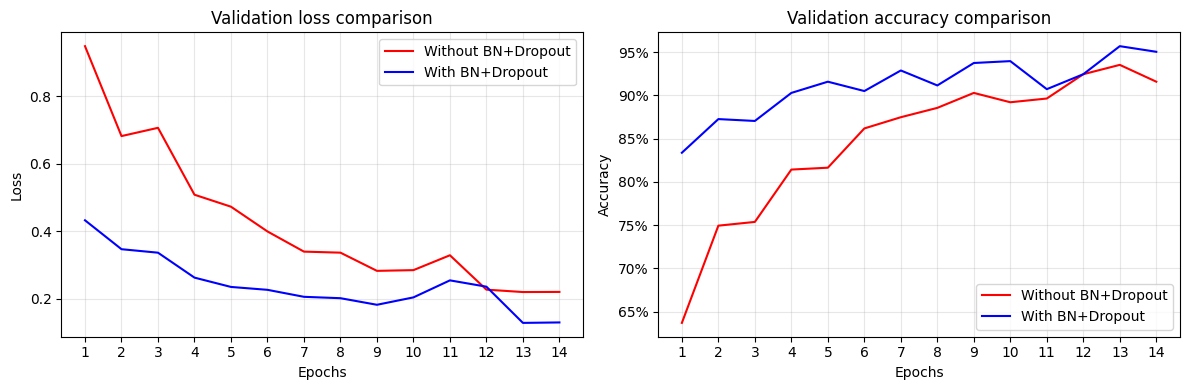

In [ ]:
epochs = np.arange(epoch_number) + 1

# --- Validation comparison ---
plt.figure(figsize=(12, 4))

plt.subplot(121)
plt.plot(epochs, plain_val_losses, "r", label="Without BN+Dropout")
plt.plot(epochs, reg_val_losses, "b", label="With BN+Dropout")
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title("Validation loss comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(122)
plt.plot(epochs, plain_val_accs, "r", label="Without BN+Dropout")
plt.plot(epochs, reg_val_accs, "b", label="With BN+Dropout")
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x * 100:.0f}%"))
plt.title("Validation accuracy comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


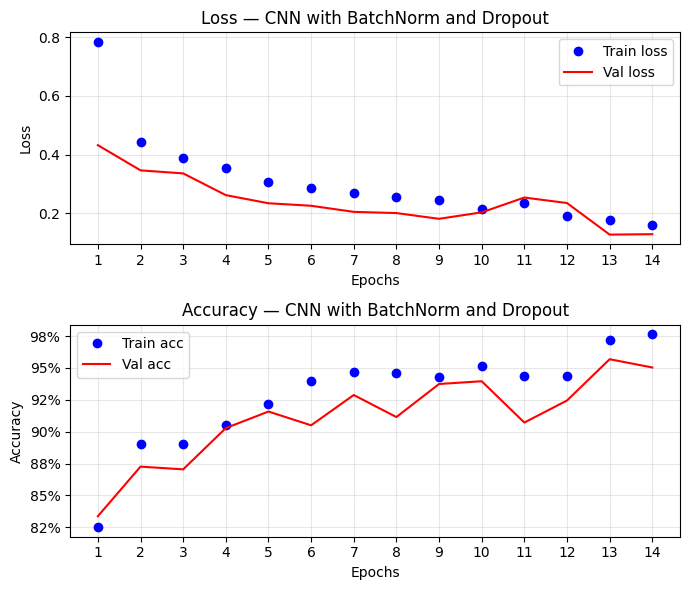

In [ ]:
# --- Training curves of the best model ---
plt.figure(figsize=(7, 6))

plt.subplot(211)
plt.plot(epochs, best_train_losses, "bo", label="Train loss")
plt.plot(epochs, best_val_losses, "r", label="Val loss")
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.title(f"Loss — {best_model_name}")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(212)
plt.plot(epochs, best_train_accs, "bo", label="Train acc")
plt.plot(epochs, best_val_accs, "r", label="Val acc")
plt.gca().xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x * 100:.0f}%"))
plt.title(f"Accuracy — {best_model_name}")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Evaluate Model on Test Set


In [ ]:
all_preds, all_labels = [], []
best_model.eval()

with torch.no_grad():
    for x, y in te_dl:
        x = x.to(device)
        _, argmax = best_model(x).max(-1)
        all_preds.extend(argmax.cpu().numpy().tolist())
        all_labels.extend(y.numpy().tolist())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_accuracy = float(np.mean(all_preds == all_labels))

# Per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    all_labels, all_preds, labels=np.arange(num_classes), zero_division=0
)

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="macro", zero_division=0
)

wt_p, wt_r, wt_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average="weighted", zero_division=0
)

print(f"Test Accuracy        : {test_accuracy:.4f}")
print(f"Macro  Precision     : {macro_p:.4f}")
print(f"Macro  Recall        : {macro_r:.4f}")
print(f"Macro  F1 Score      : {macro_f1:.4f}")
print(f"Weighted Precision   : {wt_p:.4f}")
print(f"Weighted Recall      : {wt_r:.4f}")
print(f"Weighted F1 Score    : {wt_f1:.4f}")
print()

for i in range(num_classes):
    print(
        f"Class: {class_names[i]:26s} | Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | F1: {f1[i]:.4f} | Support: {int(support[i])}"
    )


Test Accuracy        : 0.9384
Macro  Precision     : 0.9386
Macro  Recall        : 0.9396
Macro  F1 Score      : 0.9390
Weighted Precision   : 0.9381
Weighted Recall      : 0.9384
Weighted F1 Score    : 0.9382

Class: Pineapple__leaf_blight     | Precision: 0.9125 | Recall: 0.9012 | F1: 0.9068 | Support: 243
Class: Pineapple_fusarium         | Precision: 0.9177 | Recall: 0.8983 | F1: 0.9079 | Support: 236
Class: Pineapple_healthy          | Precision: 0.9828 | Recall: 0.9913 | F1: 0.9871 | Support: 231
Class: Pineapple_mealybug_wilt    | Precision: 0.9414 | Recall: 0.9676 | F1: 0.9543 | Support: 216


## 7b. Confusion Matrix & Per-Class Analysis


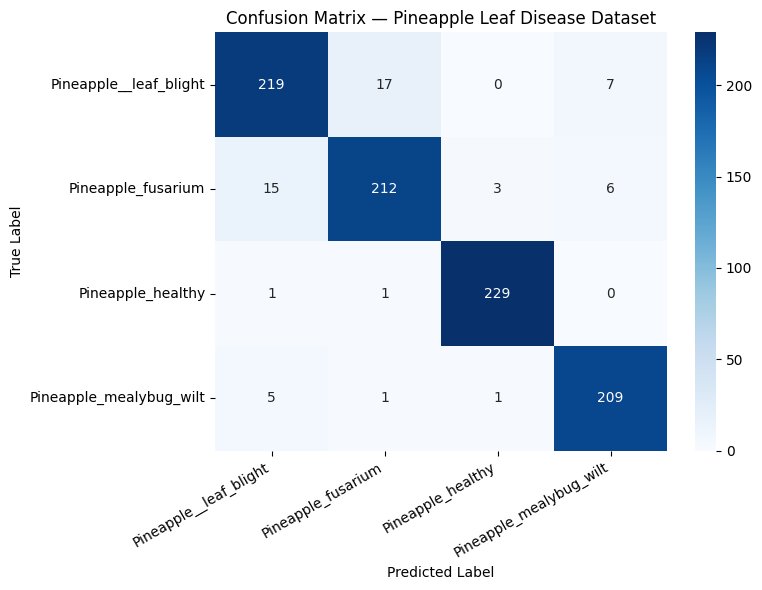


Best  performing class: Pineapple_healthy          | Accuracy: 0.9913 | F1: 0.9871
Worst performing class: Pineapple_fusarium         | Accuracy: 0.8983 | F1: 0.9079


In [ ]:
cm = confusion_matrix(all_labels, all_preds)
class_accuracy = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix — Pineapple Leaf Disease Dataset")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

best_class_ix = int(np.argmax(class_accuracy))
worst_class_ix = int(np.argmin(class_accuracy))

print(
    f"\nBest  performing class: {class_names[best_class_ix]:26s} | "
    f"Accuracy: {class_accuracy[best_class_ix]:.4f} | F1: {f1[best_class_ix]:.4f}"
)
print(
    f"Worst performing class: {class_names[worst_class_ix]:26s} | "
    f"Accuracy: {class_accuracy[worst_class_ix]:.4f} | F1: {f1[worst_class_ix]:.4f}"
)


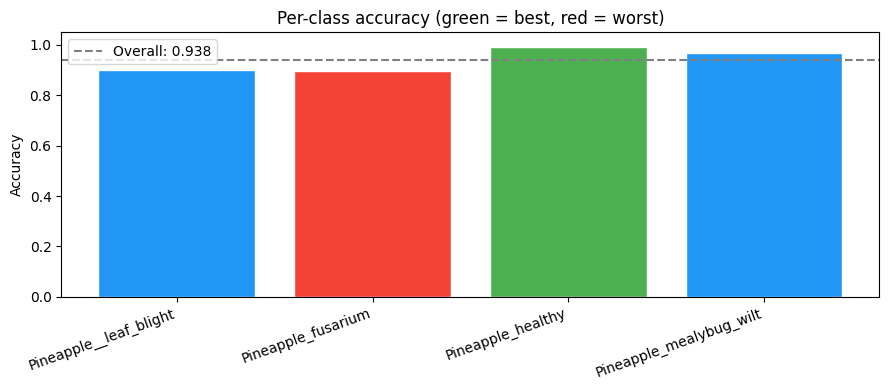

In [ ]:
# --- Per-class accuracy bar chart ---
plt.figure(figsize=(9, 4))
colors = ["#2196F3" if i != worst_class_ix else "#F44336" for i in range(num_classes)]
colors[best_class_ix] = "#4CAF50"
plt.bar(class_names, class_accuracy, color=colors, edgecolor="white")
plt.ylim(0.0, 1.05)
plt.ylabel("Accuracy")
plt.title("Per-class accuracy (green = best, red = worst)")
plt.xticks(rotation=20, ha="right")
plt.axhline(test_accuracy, color="gray", linestyle="--", label=f"Overall: {test_accuracy:.3f}")
plt.legend()
plt.tight_layout()
plt.show()


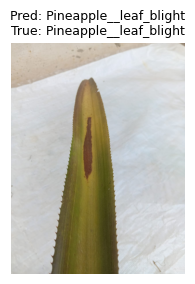

In [ ]:
# --- Single prediction example ---
ix = int(torch.randint(0, len(te_paths), ()).item())
raw_pil = Image.open(te_paths[ix]).convert("RGB")
img_norm = eval_transform(raw_pil).unsqueeze(0).to(device)

with torch.no_grad():
    scores = best_model(img_norm).cpu().numpy()

pred_cls = class_names[int(scores[0].argmax())]
true_cls = class_names[te_targets[ix]]

plt.figure(figsize=(3, 3))
plt.imshow(raw_pil)
plt.title(f"Pred: {pred_cls}\nTrue: {true_cls}", fontsize=9)
plt.axis("off")
plt.show()


Total misclassified: 57


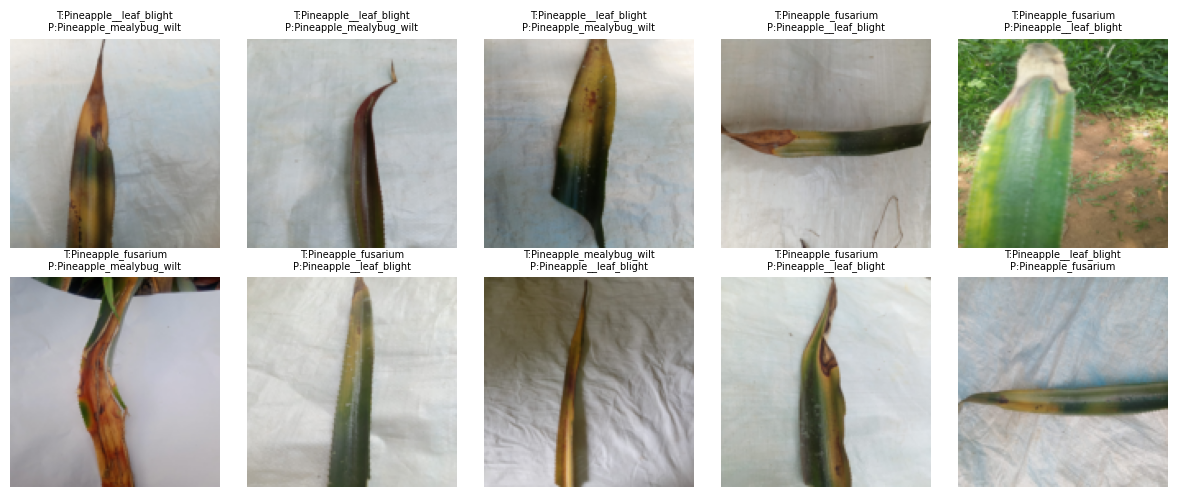

In [ ]:
# --- Show misclassified samples ---
misclassified = []
best_model.eval()

with torch.no_grad():
    for images, labels in te_dl:
        images_dev = images.to(device)
        _, preds = best_model(images_dev).max(1)
        for img, true, pred in zip(images, labels, preds.cpu()):
            if int(true) != int(pred):
                misclassified.append((img, int(true), int(pred)))

print(f"Total misclassified: {len(misclassified)}")

num_show = min(10, len(misclassified))
if num_show > 0:
    num_rows = 2 if num_show > 5 else 1
    num_cols = int(np.ceil(num_show / num_rows))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2.4, num_rows * 2.5))
    axes = np.array(axes).flatten()

    mean_t = torch.tensor(IMG_MEAN).view(3, 1, 1)
    std_t = torch.tensor(IMG_STD).view(3, 1, 1)

    for idx in range(num_show):
        img, true, pred = misclassified[idx]
        img_disp = (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
        axes[idx].imshow(img_disp)
        axes[idx].set_title(f"T:{class_names[true]}\nP:{class_names[pred]}", fontsize=7)
        axes[idx].axis("off")
    for idx in range(num_show, len(axes)):
        axes[idx].axis("off")

    plt.tight_layout()
    plt.show()


## 8. Save Trained Model Weights


In [ ]:
final_model_file = os.path.join(WORK_DIR, "CNN_pineapple_best.pth")
torch.save(best_model.state_dict(), final_model_file)

# Verify: reload and check summary
saved_model, _, _ = get_model(with_batch_norm=best_with_reg, with_dropout=best_with_reg)
saved_model.load_state_dict(torch.load(final_model_file, map_location=device))
saved_model.eval()

total_trainable_params = sum(p.numel() for p in saved_model.parameters() if p.requires_grad)
print(f"Saved to: {final_model_file}")
summary(saved_model, (3, img_size, img_size))

Saved to: /content/drive/MyDrive/CVPR DATASET/CNN_pineapple_best.pth
----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
       BatchNorm2d-2         [-1, 32, 128, 128]              64
              ReLU-3         [-1, 32, 128, 128]               0
            Conv2d-4         [-1, 32, 128, 128]           9,248
       BatchNorm2d-5         [-1, 32, 128, 128]              64
              ReLU-6         [-1, 32, 128, 128]               0
         MaxPool2d-7           [-1, 32, 64, 64]               0
         Dropout2d-8           [-1, 32, 64, 64]               0
            Conv2d-9           [-1, 64, 64, 64]          18,496
      BatchNorm2d-10           [-1, 64, 64, 64]             128
             ReLU-11           [-1, 64, 64, 64]               0
           Conv2d-12           [-1, 64, 64, 64]          36,928
      BatchNorm2d-13           [-1

## 9. Analysis & Discussion of Results


In [ ]:
print("=== Analysis and Discussion of Results ===")
print(f"Final selected model : {best_model_name}")
print(f"Test accuracy        : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print(f"Macro F1 Score       : {macro_f1:.4f}")
print()
print(
    f"Best  performing class: {class_names[best_class_ix]}  "
    f"(Acc: {class_accuracy[best_class_ix]:.4f}, F1: {f1[best_class_ix]:.4f})"
)
print(
    f"Worst performing class: {class_names[worst_class_ix]}  "
    f"(Acc: {class_accuracy[worst_class_ix]:.4f}, F1: {f1[worst_class_ix]:.4f})"
)
print()
print(f"Best val acc without BN+Dropout : {plain_best_val_acc:.4f}")
print(f"Best val acc with    BN+Dropout : {reg_best_val_acc:.4f}")
print()
if best_with_reg:
    print("Batch normalization and dropout improved generalization, so the regularized model was selected.")
else:
    print("The plain model achieved better validation accuracy in this run.")
print()
print("Key observations:")
print("  - Natural field lighting and background clutter make pineapple leaf classification more challenging than studio datasets.")
print("  - Visually similar disease symptoms (e.g., leaf spots/blight vs. wilting discoloration) account for most misclassifications.")
print("  - BatchNorm stabilizes training; Dropout2d/Dropout reduces overfitting at later epochs.")
print("  - ReduceLROnPlateau (LRS) lowers the learning rate automatically when validation loss plateaus.")
print()
print("Future improvements:")
print("  - Training-only data augmentation (random flip, rotation, color jitter)")
print("  - Higher input resolution (224x224) or residual skip connections")
print("  - Label smoothing or class weighting if any class is under-represented")
print()
print("=" * 65)
print("CVPR MIDTERM ASSIGNMENT SUBMISSION SUMMARY")
print("=" * 65)
print(f"4.  Dataset Name              : Pineapple Leaf Disease Dataset")
print(f"5.  Dataset Description       : Real-world RGB smartphone images of healthy and diseased pineapple leaves across 4 classes.")
print(f"6.  Number of Classes/Labels  : {num_classes}")
print(f"7.  Dataset Link              : https://data.mendeley.com/datasets/gc5f8dfgrt")
print(f"8.  Images Used in Training   : {len(tr_paths) + len(val_paths)} (Train: {len(tr_paths)}, Val: {len(val_paths)})")
print(f"9.  Images Used in Testing    : {len(te_paths)}")
print(f"10. Best Accuracy Value (%)   : {test_accuracy * 100:.2f}")
print(f"11. Best Loss Value           : {best_loss_value:.4f}")
print(f"12. Number of Epochs Trained  : {epoch_number}")
print(f"13. Regularization Used       : {'Dropout in Neural Networks' if best_with_reg else 'N/A'}")
print(f"14. Used Learning Rate        : LRS (ReduceLROnPlateau, initial lr={learning_rate})")
print(f"15. Total Trainable Params    : {total_trainable_params}")
print("=" * 65)


=== Analysis and Discussion of Results ===
Final selected model : CNN with BatchNorm and Dropout
Test accuracy        : 0.9384 (93.84%)
Macro F1 Score       : 0.9390

Best  performing class: Pineapple_healthy  (Acc: 0.9913, F1: 0.9871)
Worst performing class: Pineapple_fusarium  (Acc: 0.8983, F1: 0.9079)

Best val acc without BN+Dropout : 0.9352
Best val acc with    BN+Dropout : 0.9568

Batch normalization and dropout improved generalization, so the regularized model was selected.

Key observations:
  - Natural field lighting and background clutter make pineapple leaf classification more challenging than studio datasets.
  - Visually similar disease symptoms (e.g., leaf spots/blight vs. wilting discoloration) account for most misclassifications.
  - BatchNorm stabilizes training; Dropout2d/Dropout reduces overfitting at later epochs.
  - ReduceLROnPlateau (LRS) lowers the learning rate automatically when validation loss plateaus.

Future improvements:
  - Training-only data augmentatio